# 09. Отдельный аудит числовых аномалий METAR

## 1. Протокол и границы проверки

Аудит выполнен по согласованному решению до исправления значений или исключения
записей. Проверены все 93 блока станция–год. Кандидаты: четыре наблюдаемых
экстремума, QNH вне диагностического интервала 850–1100 гПа и превышение точки
росы над температурой. Этот интервал — средство поиска, а не норматив или
правило очистки. Проверка не является исчерпывающей физической валидацией.

Для четырех экстремумов показаны сообщения той же станции в пределах ±3 часов.
Последующие сообщения используются только для диагностики и не становятся
признаками на C40. Отбор не зависит от исхода посадки.


In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
from html import escape
from cycler import cycler

BASE = Path.cwd().resolve()
while not (BASE / 'reports/03_pilot_manifest.json').exists():
    if BASE == BASE.parent:
        raise FileNotFoundError('Не найдена папка europe/weather с выполненным пилотом')
    BASE = BASE.parent
PROJECT = BASE.parents[1]
R, F, DATA = BASE / 'reports', BASE / 'figures', BASE / 'data'
F.mkdir(exist_ok=True)
sys.path.insert(0, str(BASE / 'scripts'))
manifest = json.loads((R / '03_pilot_manifest.json').read_text(encoding='utf8'))
def sha(path):
    with path.open('rb') as stream:
        return hashlib.file_digest(stream, 'sha256').hexdigest()
assert sha(PROJECT / 'europe/data/analytical/06_05_cases_excluded.parquet') == manifest['input_sha256']
for source in manifest['downloads']:
    path = DATA / 'raw' / f"{source['airport']}_{source['month']}.csv"
    assert sha(path) == source['sha256']

GREEN, CORAL, LIGHT_GREEN, LIGHT_CORAL = '#00897B', '#D65A4A', '#80CBC4', '#E69A90'
plt.rcParams.update({'figure.dpi':120, 'font.size':11, 'axes.spines.top':False,
    'axes.spines.right':False, 'axes.grid':True, 'grid.alpha':.16,
    'axes.prop_cycle':cycler(color=[CORAL, GREEN, LIGHT_CORAL, LIGHT_GREEN])})
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_rows', 30)
pd.set_option('display.max_colwidth', 100)
def save(name):
    plt.tight_layout()
    for ext in ['png', 'svg']:
        plt.savefig(F / f'{name}.{ext}', bbox_inches='tight')
    plt.show()
def readable_table(frame):
    html = frame.to_html(index=False, escape=True)
    display(HTML('<div style="max-width:100%;overflow:auto">' + html + '</div>'))


In [2]:
audit=json.loads((R/'15_numeric_audit.json').read_text(encoding='utf8'))
cases=pd.read_csv(R/'12_full_extreme_value_examples.csv')
candidates=pd.read_csv(R/'15_numeric_candidates.csv')
neighbors=pd.read_csv(R/'15_extreme_neighbors.csv')
checks=pd.read_csv(R/'15_source_archive_checks.csv')
assert audit['rows_changed']==audit['rows_deleted']==0
assert candidates.metar_id.nunique()==audit['unique_candidates']
display(pd.DataFrame([audit]))
readable_table(cases[['station','metar_utc','metar','review_reason','extreme_value','linked_rows','linked_go_arounds']])
readable_table(candidates)


,scope,unique_candidates,candidate_reason_counts,rows_changed,rows_deleted,independent_source_verified
0,93 station-year blocks; QNH diagnostic interval and dewpoint-temperature consistency; four obser...,18,"{'dewpoint_above_temperature': 14, 'observed_extreme': 4, 'qnh_outside_diagnostic_interval': 2}",0,0,False


station,metar_utc,metar,review_reason,extreme_value,linked_rows,linked_go_arounds
EHAM,2021-01-19 11:55:00+00:00,EHAM 191155Z 25018G30KT 210V280 7000 -DZRA FEW006 BKN008 10/M80 Q1002 BECMG 9999 NSW BKN014,dewpoint_c_minimum,-80.0,2,0
ESSA,2021-04-08 13:50:00+00:00,ESSA 081350Z 32005KT 9999 FEW012 BKN900 06/M07 Q1005 R08/09//95 R19L/09//95 NOSIG,cloud_ceiling_ft_maximum,90000.0,3,0
LIMC,2020-11-01 18:20:00+00:00,LIMC 011820Z VRB01KT 0100 R35R/0400D R17L/0400D R35L/0500N FG VV001 11/11 Q0122 NOSIG,qnh_hpa_minimum,122.0,1,0
LIMC,2020-10-30 12:20:00+00:00,LIMC 301220Z 24003KT CAVOK 17/11 Q1202 NOSIG,qnh_hpa_maximum,1202.0,1,0


metar_id,station,metar_utc,metar,qnh_hpa,temperature_c,dewpoint_c,cloud_ceiling_ft,decoded_candidate,core_validated,reason,linked_rows,linked_go_arounds
5225df93cd6502c8d398e5cc8a34f896cc1f8c6fc511b5b2c00a83241a24fd82,EHAM,2019-10-31 13:25:00+00:00,EHAM 311325Z 09009KT 050V120 CAVOK 10/12 Q1021 NOSIG,1021.0,10.0,12.0,NaN,True,True,dewpoint_above_temperature,11,0
c26eff211c7d01b9563f39a342996cc4fc751b08d0162ad35a66bc39ea7327c0,EHAM,2021-01-19 11:55:00+00:00,EHAM 191155Z 25018G30KT 210V280 7000 -DZRA FEW006 BKN008 10/M80 Q1002 BECMG 9999 NSW BKN014,1002.0,10.0,-80.0,800.0,True,True,observed_extreme,2,0
3aa11421d9e692a4b3cf9d6729e195564959367c8dc7cfa6aea7ea9ae4d0b267,EIDW,2019-02-24 02:00:00+00:00,EIDW 240200Z 11004KT 7000 BCFG FEW005 00/01 Q1032 TEMPO 1500,1032.0,0.0,1.0,NaN,True,True,dewpoint_above_temperature,1,0
aae4b1ef816a56897b6e6eb04b27072e24ddb3f0b7b1636be4f60c2b8b6a9cb1,EIDW,2019-11-24 02:30:00+00:00,EIDW 240230Z 28007KT 9999 FEW005 BKN040 06/07 Q1001 NOSIG,1001.0,6.0,7.0,4000.0,True,True,dewpoint_above_temperature,0,0
af20a13b04a6af07ecca596d44a2fba0f1aeb8c945c3823b5518a524dd854c28,EIDW,2020-05-09 06:00:00+00:00,EIDW 090600Z 07004KT CAVOK 08/09 Q1015 NOSIG,1015.0,8.0,9.0,NaN,True,True,dewpoint_above_temperature,0,0
bd54c78d030f03527cc9ce2c342c0953aa12ddd038b339c53ee21389564a2efa,EIDW,2020-06-15 05:30:00+00:00,EIDW 150530Z VRB02KT 9999 FEW020 10/11 Q1016 NOSIG,1016.0,10.0,11.0,NaN,True,True,dewpoint_above_temperature,0,0
3c64f34519a174aff63dd09c4a0a7babe9c21d08b6b0b68d56cb5972d8f3eb9e,EIDW,2020-08-11 04:30:00+00:00,EIDW 110430Z 28005KT 5000 BKN010 12/13 Q1017 NOSIG,1017.0,12.0,13.0,1000.0,True,True,dewpoint_above_temperature,0,0
abccfe5b2d256617c7ddc2c322704ecbb8560f66a9d343f1b94a164688e2709a,EIDW,2020-11-29 01:30:00+00:00,EIDW 290130Z 08005KT 9999 FEW015 BKN022 05/06 Q1023 NOSIG,1023.0,5.0,6.0,2200.0,True,True,dewpoint_above_temperature,1,0
4608a5fe2b1cae6320cadfbd327340682866152671c98a30699c702413d7eeb6,EIDW,2021-04-26 05:00:00+00:00,EIDW 260500Z 34003KT 9999 FEW015 00/01 Q1025 NOSIG,1025.0,0.0,1.0,NaN,True,True,dewpoint_above_temperature,0,0
c0a8a298430f5e7b86af3fae32336ced226a9a2e2b252882423c13511cf9bb2d,EIDW,2022-08-01 06:00:00+00:00,EIDW 010600Z 29005KT 1200 R16/0700D R28L/2000N R10/0550V0750D BR FEW001 09/11 Q1018 BECMG 4000,1018.0,9.0,11.0,NaN,True,True,dewpoint_above_temperature,5,0


## 2. Сопоставление с соседними наблюдениями

Красным обозначено проверяемое сообщение, зеленым — соседние наблюдения.
Линия соединяет дискретные сообщения и не означает интерполяцию измерений.
Единицы и шкалы различаются между панелями. Резкое отклонение требует проверки
происхождения; оно само по себе не устанавливает правильное значение.


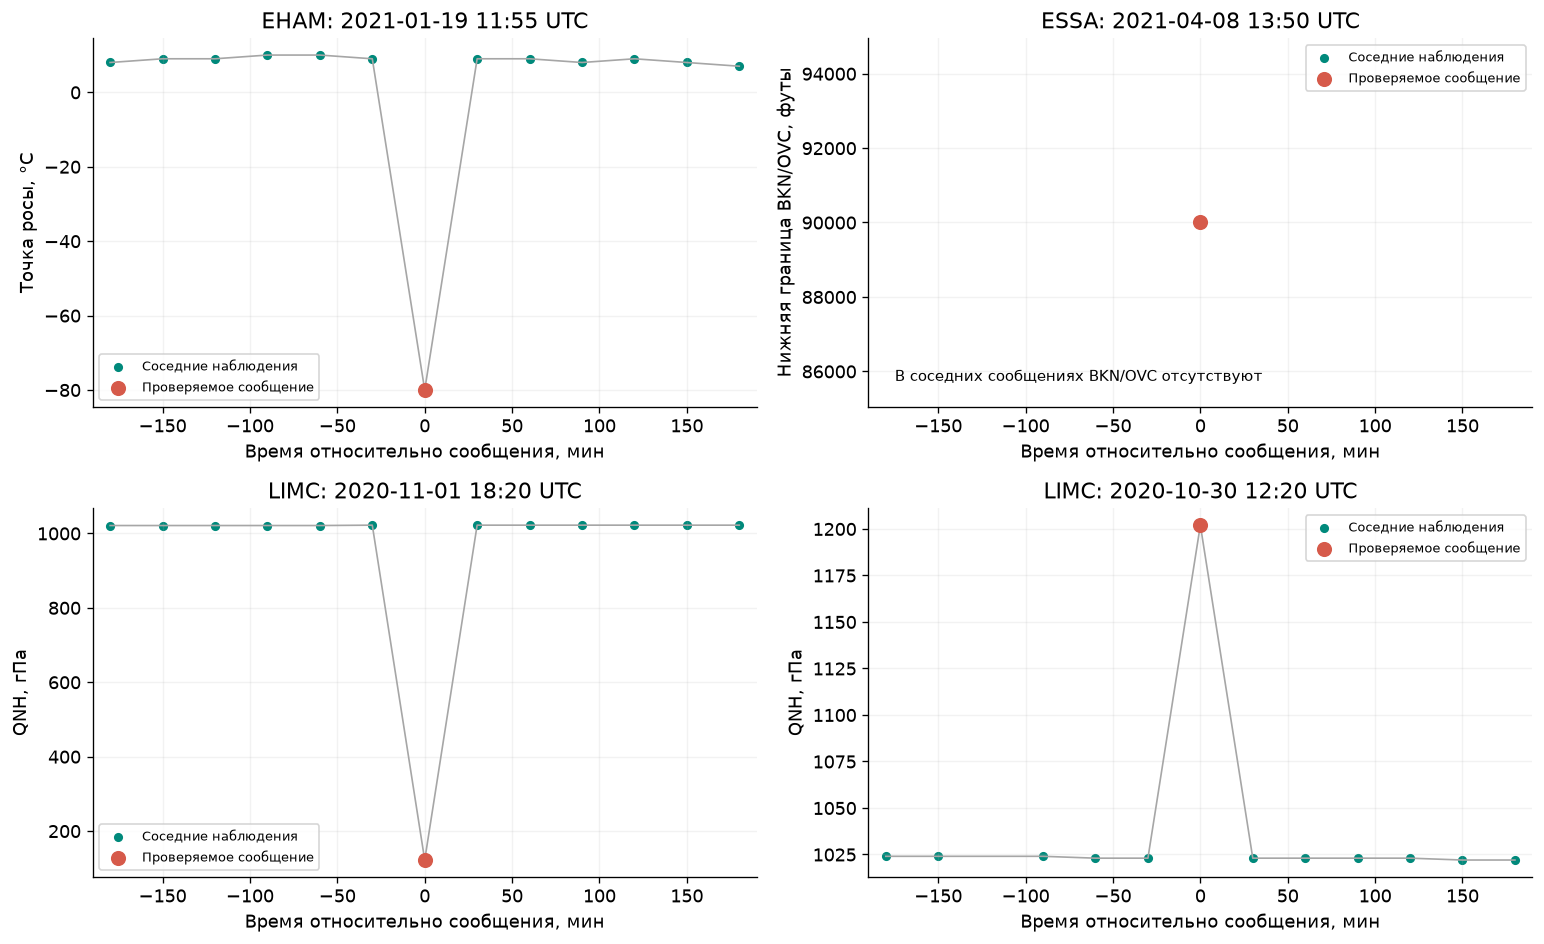

### EHAM, 2021-01-19 11:55:00+00:00

metar_utc,metar,qnh_hpa,temperature_c,dewpoint_c,cloud_ceiling_ft
2021-01-19 08:55:00+00:00,EHAM 190855Z 24025G36KT 4000 RADZ FEW005 SCT007 BKN008 09/08 Q1001 TEMPO 8000 -DZRA BKN012,1001.0,9.0,8.0,800.0
2021-01-19 09:25:00+00:00,EHAM 190925Z 24024G35KT 4000 -DZRA FEW005 SCT006 BKN008 09/09 Q1001 TEMPO 6000,1001.0,9.0,9.0,800.0
2021-01-19 09:55:00+00:00,EHAM 190955Z 25022KT 220V290 7000 -RADZ FEW005 SCT006 BKN008 10/09 Q1002 BECMG 9999 NSW BKN014,1002.0,10.0,9.0,800.0
2021-01-19 10:25:00+00:00,EHAM 191025Z 26019G31KT 230V290 8000 -RADZ FEW007 BKN008 10/10 Q1002 BECMG BKN014 TEMPO 6000,1002.0,10.0,10.0,800.0
2021-01-19 10:55:00+00:00,EHAM 191055Z 25020KT 4000 DZRA FEW007 BKN008 10/10 Q1002 BECMG 9999 NSW BKN014,1002.0,10.0,10.0,800.0
2021-01-19 11:25:00+00:00,EHAM 191125Z 27017KT 3000 DZRA FEW006 BKN008 09/09 Q1003 BECMG 25025G36KT 9999 NSW BKN012,1003.0,9.0,9.0,800.0
2021-01-19 11:55:00+00:00,EHAM 191155Z 25018G30KT 210V280 7000 -DZRA FEW006 BKN008 10/M80 Q1002 BECMG 9999 NSW BKN014,1002.0,10.0,-80.0,800.0
2021-01-19 12:25:00+00:00,EHAM 191225Z 24024KT 210V270 9999 FEW008 BKN011 10/09 Q1002 NOSIG,1002.0,10.0,9.0,1100.0
2021-01-19 12:55:00+00:00,COR EHAM 191255Z 24022G35KT 210V280 9999 SCT008 BKN011 BKN019 10/09 Q1002 NOSIG,1002.0,10.0,9.0,1100.0
2021-01-19 13:25:00+00:00,EHAM 191325Z 24022KT 9999 BKN008 BKN011 10/08 Q1002 BECMG BKN012,1002.0,10.0,8.0,800.0


### ESSA, 2021-04-08 13:50:00+00:00

metar_utc,metar,qnh_hpa,temperature_c,dewpoint_c,cloud_ceiling_ft
2021-04-08 10:50:00+00:00,ESSA 081050Z 25012KT CAVOK 06/M08 Q1006 R08/09//95 R19L/09//95 NOSIG,1006.0,6.0,-8.0,NaN
2021-04-08 11:20:00+00:00,ESSA 081120Z 28011KT 250V310 CAVOK 06/M09 Q1006 R08/09//95 R19L/09//95 NOSIG,1006.0,6.0,-9.0,NaN
2021-04-08 11:50:00+00:00,ESSA 081150Z 27010KT CAVOK 06/M10 Q1005 R08/09//95 R19L/09//95 NOSIG,1005.0,6.0,-10.0,NaN
2021-04-08 12:20:00+00:00,ESSA 081220Z 27011KT CAVOK 06/M10 Q1005 R08/09//95 R19L/09//95 NOSIG,1005.0,6.0,-10.0,NaN
2021-04-08 12:50:00+00:00,ESSA 081250Z 27011KT CAVOK 06/M09 Q1005 R08/09//95 R19L/09//95 NOSIG,1005.0,6.0,-9.0,NaN
2021-04-08 13:20:00+00:00,ESSA 081320Z 29013KT 9999 R01L///// R19R/P1500N R01R/P1500N R19L/P1500N -SN SCT008CB 04/M06 Q1005 R08/09//95 R19L/09//95 NOSIG,1005.0,4.0,-6.0,NaN
2021-04-08 13:50:00+00:00,ESSA 081350Z 32005KT 9999 FEW012 BKN900 06/M07 Q1005 R08/09//95 R19L/09//95 NOSIG,1005.0,6.0,-7.0,90000.0
2021-04-08 14:20:00+00:00,ESSA 081420Z 24007KT 200V290 CAVOK 06/M08 Q1005 R08/09//95 R19L/09//95 NOSIG,1005.0,6.0,-8.0,NaN
2021-04-08 14:50:00+00:00,ESSA 081450Z 32009KT CAVOK 06/M06 Q1005 R08/09//95 R19L/09//95 NOSIG,1005.0,6.0,-6.0,NaN
2021-04-08 15:20:00+00:00,ESSA 081520Z 28005KT 210V340 CAVOK 06/M06 Q1004 R08/09//95 R19L/09//95 NOSIG,1004.0,6.0,-6.0,NaN


### LIMC, 2020-11-01 18:20:00+00:00

...

metar_utc,metar,temperature_c,dewpoint_c
2022-12-12 12:30:00+00:00,EIDW 121230Z 36001KT 0200 R28L/0400 R10R/0400 R28R/0500 FZFG BKN001 BKN002 M01/M01 Q1006 NOSIG,-1.0,-1.0
2022-12-12 13:00:00+00:00,EIDW 121300Z VRB01KT 0300 R28L/0400 R10R/0550U R28R/0450D FZFG SCT001 BKN002 M00/M00 Q1006 NOSIG,-0.0,-0.0
2022-12-12 13:30:00+00:00,EIDW 121330Z VRB02KT 0300 R28L/0400N R10R/0500N R28R/0500N FG SCT001 BKN002 00/00 Q1006 NOSIG,0.0,0.0
2022-12-12 14:00:00+00:00,EIDW 121400Z VRB02KT 0200 R28L/0600N R10R/0750U R28R/0400N FG SCT001 BKN002 01/00 Q1006 NOSIG,1.0,0.0
2022-12-12 14:30:00+00:00,EIDW 121430Z VRB03KT 0200 R28L/1300D R10R/0400D R28R/0400N FG SCT001 BKN002 00/00 Q1006 NOSIG,0.0,0.0
2022-12-12 15:00:00+00:00,EIDW 121500Z VRB03KT 0150 R28L/0800D R10R/0450 R28R/0350N FG BKN001 BKN002 M00/M00 Q1006 NOSIG,-0.0,-0.0
2022-12-12 15:30:00+00:00,EIDW 121530Z VRB03KT 0150 R28L/0450U R10R/0325N R28R/0350N FG BKN001 BKN002 M01/M00 Q1006 NOSIG,-1.0,-0.0
2022-12-12 16:00:00+00:00,EIDW 121600Z VRB02KT 0100 R28L/0400D R10R/0350N R28R/0350N FZFG BKN001 BKN002 M01/M01 Q1006 NOSIG,-1.0,-1.0
2022-12-12 16:30:00+00:00,EIDW 121630Z 36001KT 0100 R28L/0550N R10R/0450N R28R/0450N FZFG BKN001 BKN002 M01/M01 Q1006 NOSIG,-1.0,-1.0
2022-12-12 17:00:00+00:00,EIDW 121700Z 35005KT 320V020 0150 R28L/0600N R10R/0550U R28R/0550N FZFG BKN001 BKN002 M01/M02 Q1007 NOSIG,-1.0,-2.0


### Проверка согласованности температуры: LIMC, 2020-10-30 23:50:00+00:00

metar_utc,metar,temperature_c,dewpoint_c
2020-10-30 20:50:00+00:00,LIMC 302050Z VRB02KT 9999 R35R/1100U R17L/1400N R35L/1400D BCFG NSC 09/08 Q1024 NOSIG,9.0,8.0
2020-10-30 21:20:00+00:00,LIMC 302120Z 01005KT 8000 R35R/1200U R17L/1400D R35L/P1500N BCFG NSC 09/08 Q1025 NOSIG,9.0,8.0
2020-10-30 21:50:00+00:00,LIMC 302150Z 01005KT 6000 R35R/P1500N R17L/0700U R35L/P1500N BCFG NSC 07/07 Q1025 NOSIG,7.0,7.0
2020-10-30 22:20:00+00:00,LIMC 302220Z 02003KT 6000 R35R/P1500N R17L/0700U R35L/P1500N BCFG NSC 08/07 Q1024 NOSIG,8.0,7.0
2020-10-30 22:50:00+00:00,LIMC 302250Z 02003KT 6000 R35R/1000D R17L/1200D R35L/P1500N BCFG NSC 08/07 Q1024 NOSIG,8.0,7.0
2020-10-30 23:20:00+00:00,LIMC 302320Z 36005KT 5000 R35R/0500N R17L/1300U R35L/P1500N BCFG NSC 08/07 Q1024 NOSIG,8.0,7.0
2020-10-30 23:50:00+00:00,LIMC 302350Z 01005KT 5000 R35R/0600D R17L/0700D R35L/P1500N BCFG NSC 07/08 Q1024 NOSIG,7.0,8.0
2020-10-31 00:20:00+00:00,LIMC 310020Z 35006KT 5000 R35R/1400D R17L/0700N R35L/P1500N BCFG NSC 06/06 Q1024 NOSIG,6.0,6.0
2020-10-31 00:50:00+00:00,LIMC 310050Z 02004KT 5000 R35R/1200N R17L/1400N R35L/P1500N BCFG NSC 06/05 Q1024 NOSIG,6.0,5.0
2020-10-31 01:20:00+00:00,LIMC 310120Z 01005KT 5000 R35R/1400U R17L/1300U R35L/P1500N BCFG NSC 06/06 Q1024 NOSIG,6.0,6.0


### Проверка согласованности температуры: LIRF, 2022-11-25 18:50:00+00:00

metar_utc,metar,temperature_c,dewpoint_c
2022-11-25 15:50:00+00:00,LIRF 251550Z 14008KT 7000 RA SCT010 SCT025 14/13 Q1018 NOSIG,14.0,13.0
2022-11-25 16:20:00+00:00,LIRF 251620Z 14007KT 120V180 7000 RA SCT010 BKN035 14/13 Q1018 NOSIG,14.0,13.0
2022-11-25 16:50:00+00:00,LIRF 251650Z 12006KT 7000 RA SCT010 BKN035 13/13 Q1018 NOSIG,13.0,13.0
2022-11-25 17:20:00+00:00,LIRF 251720Z 12008KT 7000 RA SCT010 SCT040 13/13 Q1017 NOSIG,13.0,13.0
2022-11-25 17:50:00+00:00,LIRF 251750Z 12010KT 8000 -RA FEW020 SCT050 13/12 Q1017 RERA NOSIG,13.0,12.0
2022-11-25 18:20:00+00:00,LIRF 251820Z 13012KT 8000 -RA FEW010 SCT050 12/11 Q1017 NOSIG,12.0,11.0
2022-11-25 18:50:00+00:00,COR LIRF 251850Z 13015KT 9000 -RA FEW050 12/15 Q1016 NOSIG,12.0,15.0
2022-11-25 19:20:00+00:00,LIRF 251920Z 14015KT 9000 -RA SCT050 12/11 Q1016 NOSIG,12.0,11.0
2022-11-25 19:50:00+00:00,LIRF 251950Z 10009KT 9000 -RA FEW050 12/11 Q1017 NOSIG,12.0,11.0
2022-11-25 20:20:00+00:00,LIRF 252020Z 09008KT 9999 -RA SCT050 12/11 Q1017 NOSIG,12.0,11.0


In [3]:
neighbors['metar_utc']=pd.to_datetime(neighbors.metar_utc,utc=True)
fig,axes=plt.subplots(2,2,figsize=(13,8))
units={'qnh_hpa':'QNH, гПа','dewpoint_c':'Точка росы, °C','cloud_ceiling_ft':'Нижняя граница BKN/OVC, футы'}
for ax,case in zip(axes.flat,cases.itertuples()):
    field=case.review_reason.rsplit('_',1)[0]
    part=neighbors.loc[neighbors.case_id.eq(case.metar_id)].sort_values('metar_utc')
    ax.plot(part.offset_minutes,part[field],'-',color='0.65',linewidth=1)
    adjacent=part.loc[part.offset_minutes.ne(0)]
    ax.scatter(adjacent.offset_minutes,adjacent[field],color=GREEN,label='Соседние наблюдения',s=20)
    ax.scatter([0],[case.extreme_value],color=CORAL,s=65,zorder=3,label='Проверяемое сообщение')
    ax.set(title=f'{case.station}: {pd.Timestamp(case.metar_utc):%Y-%m-%d %H:%M} UTC',
           xlabel='Время относительно сообщения, мин',ylabel=units[field])
    ax.set_xlim(-190,190)
    if adjacent[field].notna().sum()==0:
        ax.text(.04,.07,'В соседних сообщениях BKN/OVC отсутствуют',transform=ax.transAxes,fontsize=9)
    ax.legend(fontsize=8)
save('27_numeric_extreme_neighbors')
for case in cases.itertuples():
    display(Markdown(f'### {case.station}, {case.metar_utc}'))
    readable_table(neighbors.loc[neighbors.case_id.eq(case.metar_id),['metar_utc','metar','qnh_hpa','temperature_c','dewpoint_c','cloud_ceiling_ft']])
other=candidates.loc[candidates.reason.eq('dewpoint_above_temperature')].drop_duplicates('metar_id')
for case in other.itertuples():
    display(Markdown(f'### Проверка согласованности температуры: {case.station}, {case.metar_utc}'))
    readable_table(neighbors.loc[neighbors.case_id.eq(case.metar_id),['metar_utc','metar','temperature_c','dewpoint_c']])


## 3. Проверка почасового архива источника

[Почасовой архив IEM](https://mesonet-longterm.agron.iastate.edu/archive/raw/sao/)
содержит сообщения, собранные IEM из потока National Weather Service. Для каждого
экстремума проверены час наблюдения и два следующих часа. Сжатые файлы сохранены
локально с URL, временем загрузки и SHA-256. Поиск проверяет точное совпадение
текста после нормализации пробелов; отсутствие совпадения в трех файлах не
доказывает отсутствие сообщения в источнике вообще. Поставщик тот же, поэтому
это не независимое подтверждение измерения и не доказательство ошибки станции.


In [4]:
import gzip
for row in checks.loc[checks.status.eq('retrieved')].itertuples():
    path=DATA/'anomaly_source_audit'/row.url.rsplit('/',1)[1]
    assert sha(path)==row.sha256
    raw=' '.join(gzip.decompress(path.read_bytes()).decode('utf8',errors='replace').split())
    original=cases.set_index('metar_id').loc[row.case_id,'metar']
    assert (' '.join(original.split()) in raw)==bool(row.exact_text_present)
readable_table(checks)
display(checks.groupby('case_id').agg(files_retrieved=('status',lambda x:int(x.eq('retrieved').sum())),
    files_with_exact_text=('exact_text_present','sum')))


case_id,url,archive_hour_utc,independent_provider,status,sha256,exact_text_present
c26eff211c7d01b9563f39a342996cc4fc751b08d0162ad35a66bc39ea7327c0,https://mesonet-longterm.agron.iastate.edu/archive/raw/sao/2021_01/21011911.sao.gz,2021-01-19 11:00:00+00:00,False,retrieved,0ba00e16259cf952511737cd967c91e16396754457cdb53374bfac003bf8760d,False
c26eff211c7d01b9563f39a342996cc4fc751b08d0162ad35a66bc39ea7327c0,https://mesonet-longterm.agron.iastate.edu/archive/raw/sao/2021_01/21011912.sao.gz,2021-01-19 12:00:00+00:00,False,retrieved,f193b1eb9c0239cda2950d75ff235bd5a013407b7ad7d3da8e0c2a86214df747,False
c26eff211c7d01b9563f39a342996cc4fc751b08d0162ad35a66bc39ea7327c0,https://mesonet-longterm.agron.iastate.edu/archive/raw/sao/2021_01/21011913.sao.gz,2021-01-19 13:00:00+00:00,False,retrieved,4a432bbebfe6041def28c2298ea86dc964fa75e68fdf95fb47097d886716c733,False
5e7f4b1536d4b5716a326f9e74af7805bdf2af24f258cae46db4b1fa82cbc729,https://mesonet-longterm.agron.iastate.edu/archive/raw/sao/2021_04/21040813.sao.gz,2021-04-08 13:00:00+00:00,False,retrieved,37f0606e3b8881192e0fd73036464e02737fddfe1d299c840f775f34c379ca20,False
5e7f4b1536d4b5716a326f9e74af7805bdf2af24f258cae46db4b1fa82cbc729,https://mesonet-longterm.agron.iastate.edu/archive/raw/sao/2021_04/21040814.sao.gz,2021-04-08 14:00:00+00:00,False,retrieved,e4a57ed18e07e1743dce361d6435794208c310c772d7b87c83b258795d71da86,False
5e7f4b1536d4b5716a326f9e74af7805bdf2af24f258cae46db4b1fa82cbc729,https://mesonet-longterm.agron.iastate.edu/archive/raw/sao/2021_04/21040815.sao.gz,2021-04-08 15:00:00+00:00,False,retrieved,81fdfb646a12a68ce5b7bb4a0ea9bdc1ca3ec9ebd9ab1d7ae72502b1abb7d444,False
fd337c55fdbd3a9b8a4b6fcf671dc2da6039f6564feb52a8187854f6bd4b1692,https://mesonet-longterm.agron.iastate.edu/archive/raw/sao/2020_11/20110118.sao.gz,2020-11-01 18:00:00+00:00,False,retrieved,f5d2475a236089b6805b63780a204db1e36e64b6dc393782b050bc995fc00bc0,False
fd337c55fdbd3a9b8a4b6fcf671dc2da6039f6564feb52a8187854f6bd4b1692,https://mesonet-longterm.agron.iastate.edu/archive/raw/sao/2020_11/20110119.sao.gz,2020-11-01 19:00:00+00:00,False,retrieved,133ee4428481a8f0fb03f1477a8bcdc96963f06b9fa457c14b45e15801c336d3,False
fd337c55fdbd3a9b8a4b6fcf671dc2da6039f6564feb52a8187854f6bd4b1692,https://mesonet-longterm.agron.iastate.edu/archive/raw/sao/2020_11/20110120.sao.gz,2020-11-01 20:00:00+00:00,False,retrieved,00385bc7ae7810be86074331236610cf364ebcf055c70c2bfab118704e664f0f,False
05e9ce88b3ad238073239e9f554be019f01f07570da856de79af1853a3539fef,https://mesonet-longterm.agron.iastate.edu/archive/raw/sao/2020_10/20103012.sao.gz,2020-10-30 12:00:00+00:00,False,retrieved,e7a6f38665fe2267d34766640bbf41611200cc19ada3384788638187647e776c,False


,files_retrieved,files_with_exact_text
case_id,,
05e9ce88b3ad238073239e9f554be019f01f07570da856de79af1853a3539fef,3,0
5e7f4b1536d4b5716a326f9e74af7805bdf2af24f258cae46db4b1fa82cbc729,3,0
c26eff211c7d01b9563f39a342996cc4fc751b08d0162ad35a66bc39ea7327c0,3,0
fd337c55fdbd3a9b8a4b6fcf671dc2da6039f6564feb52a8187854f6bd4b1692,3,0


## 4. Исследовательский вывод

Q0122, Q1202, 10/M80 и BKN900 присутствуют в исходных текстах, поэтому это
не результат подстановки чисел нашим декодером. Синтаксическая валидность не
означает достоверность величин. Соседние сообщения приведены для оценки
временной согласованности; исправление по ним не выполнялось.

Четыре сообщения связаны с семью обычными посадками и ни с одним GoA при
основном сопоставлении до 60 минут. Это не основание сохранять или удалять
аномалии в зависимости от метки. Числовая проверка должна учитываться отдельно
от флагов синтаксического декодирования. Независимый источник измерений и
согласованное правило обработки остаются необходимыми для исправления.


In [5]:
assert cases.linked_rows.sum()==7 and cases.linked_go_arounds.sum()==0
assert not audit['independent_source_verified']
assert sha(PROJECT/'europe/data/analytical/06_05_cases_excluded.parquet')==manifest['input_sha256']
